# 09 · Modularización: responsabilidades, contratos e imports

[Índice](00_indice_mqtt.ipynb) · [Anterior](07_python_mqtt_clase_hilos_y_ack.ipynb) · [Siguiente](10_python_pruebas_modulares.ipynb)

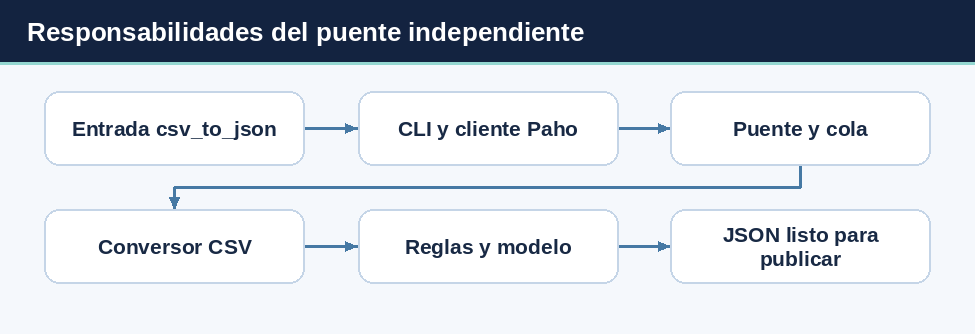

## Qué se separó y por qué

Antes `backend/scripts/csv_to_json.py` reunía constantes, conversión, modelo, callbacks y arranque.
Ahora conserva únicamente la entrada, y delega en el paquete `backend/scripts/mqtt_bridge/`.
Una carpeta se vuelve un paquete regular mediante `__init__.py`; un módulo es un archivo
Python. Una clase es un tipo definido dentro de un módulo. Un paquete no es una clase.

El objetivo práctico es encontrar y cambiar cada responsabilidad en un lugar concreto:
validar un CSV no requiere crear una conexión; crear un cliente no requiere duplicar la
conversión. Se conservaron topics, formato JSON, confirmaciones y argumentos de terminal.

```text
backend/scripts/
├── csv_to_json.py          entrada ejecutable
├── requirements.txt       dependencia externa Paho
├── mosquitto.conf         configuración del broker, proceso separado
└── mqtt_bridge/
    ├── __init__.py        identidad del paquete, sin efectos de red
    ├── settings.py        constantes
    ├── models.py          datos de una lectura convertida
    ├── converter.py       validación y conversión
    ├── bridge.py          callbacks, cola, publicaciones y ACK
    └── cli.py             argumentos y ciclo principal
```

No se movieron las funciones de C++ ni se cambió el protocolo del firmware.
La modularización no inicia Mosquitto: ese servidor sigue ejecutándose por separado.

## Grafo de imports

Una flecha `A → B` significa «A importa B», no «se envía un mensaje MQTT».

```text
csv_to_json → cli → bridge → converter → models
                   │          └───────→ settings
                   ├──────────────────→ models
                   └──────────────────→ settings
             └────────────────────────→ settings
```

`models` y `settings` no dependen del puente ni de la entrada. El grafo no tiene ciclos.
`cli.main` importa Paho en ejecución; `bridge` solo lo importa bajo TYPE_CHECKING para
anotar el tipo del cliente. La conversión se puede importar sin Paho instalado.
Esto no permite ejecutar el servicio sin instalar su dependencia: main sí la necesita.

Importar un módulo ejecuta su código de nivel superior y luego Python lo conserva en
`sys.modules` bajo el nombre de importación. No vuelve a cargar automáticamente los
cambios al editar un archivo: reinicia el proceso. No mezcles dentro del mismo proceso
imports `mqtt_bridge` y `backend.scripts.mqtt_bridge`: serían nombres de paquete distintos y
podrían crear identidades de clase distintas, aunque apunten a archivos equivalentes.

## Contratos de cada módulo

| Módulo | Entrada | Salida/efectos | Qué no hace |
|---|---|---|---|
| `settings` | Sin parámetros | Constantes de topic, tamaño, tiempos y campos | No lee config.json ni variables de entorno. |
| `models` | device_id, record_id, json_payload, tres str | Instancia inmutable por campos `ConvertedReading` | No valida el CSV ni publica. |
| `converter` | topic str, payload bytes | Lectura convertida o excepción | No abre sockets, no altera archivos. |
| `bridge` | Cliente Paho y callbacks entrantes | Cola, hilo, JSON tratado, ACK de aplicación | No decide IP ni contraseña del broker. |
| `cli` | sys.argv | Configura logger, cliente, puente y bucle de red | No reimplementa validaciones del CSV. |
| Entrada | Forma de ejecución y llamada a main | Delega al CLI | No contiene estado de mediciones. |

Las firmas detalladas, parámetros y valores de retorno de `ConvertedReading`,
`parse_measurement` y `convert_csv_message` están en el [notebook 06](06_python_conversion_y_sintaxis.ipynb).
Los seis métodos de `CsvMqttBridge`, `parse_arguments` y `main` se explican en el
[notebook 07](07_python_mqtt_clase_hilos_y_ack.ipynb).

## `settings.py`: configuración estática

Las constantes usan MAYÚSCULAS por convención, no por una restricción del lenguaje.
CSV_COLUMNS controla cabecera y orden. MEASUREMENT_FIELDS relaciona nombre, sensor y unidad.
RAW_TOPIC_FILTER se usa al suscribirse. MESSAGE_QUEUE_SIZE limita pendientes en RAM.
PUBLISH_TIMEOUT_SECONDS limita la espera del PUBACK. MQTT_KEEPALIVE_SECONDS se pasa a connect.
Los defaults de host/puerto son argumentos de cli.py, no constantes de este archivo.

Cambiar una columna solo aquí no cambia lo que genera el ESP32. Hay que coordinar ambos
lados del contrato o el conversor rechazará cabeceras. No se trasladan automáticamente
los campos a un .env ni se vuelve dinámica la configuración por modularizar.

```python
"""Constantes de transporte y contrato de mediciones."""

RAW_TOPIC_FILTER = "dispositivo/+/crudo"
MESSAGE_QUEUE_SIZE = 100
PUBLISH_TIMEOUT_SECONDS = 10
MQTT_KEEPALIVE_SECONDS = 60
CSV_COLUMNS = (
    "id", "device_id", "timestamp", "temperature", "humidity", "gas", "calibrate"
)
MEASUREMENT_FIELDS = (
    ("temperature", "DHT11", "°C"),
    ("humidity", "DHT11", "%RH"),
    ("gas", "MQ135", "ppm"),
)

```

## `models.py`: contenedor compartido

`ConvertedReading(device_id=..., record_id=..., json_payload=...)` evita pasar tres cadenas
sin indicar qué representa cada una. `frozen=True` restringe la reasignación de campos.
Los tipos no se validan automáticamente; converter construye el objeto solo tras comprobar datos.
La clase se define una sola vez y se importa donde hace falta, evitando copias que diverjan.
El ID de registro viaja en el ACK y no se añade al esquema JSON tratado.

```python
@dataclass(frozen=True)
class ConvertedReading:
    """Lectura convertida y datos necesarios para confirmar su procesamiento."""

    device_id: str
    record_id: str
    json_payload: str
```

## `converter.py`: lógica sin transporte

`parse_measurement(value)` convierte texto vacío a None, texto numérico a float finito
y levanta ValueError si es inválido. `convert_csv_message(topic,payload)` verifica topic,
UTF-8, cabecera exacta, una fila, número de campos, coincidencia de dispositivo, ID del
registro y calibrate. Usa las constantes y devuelve ConvertedReading.

El módulo no captura esos errores para fingir éxito. Los deja llegar al puente, que
registra el fallo y evita confirmar. Así, el productor conserva su fila original.
No valida fechas ISO ni todos los rangos físicos; estos límites no cambiaron con la división.
No conviene importar CsvMqttBridge aquí: invertiría la dirección de dependencias y mezclaría
conversión con el mecanismo que la usa.

## `bridge.py`: transporte y coordinación

`CsvMqttBridge(client)` conserva `self.client` y crea `self.messages`. Registra callbacks
sin ejecutarlos inmediatamente. `start()` inicia un hilo daemon para `process_messages()`.
El hilo de red en `loop_forever()` atiende on_connect y on_message; el trabajador procesa
la cola y espera PUBACK sin bloquear ese hilo de red.

| Método | Responsable de |
|---|---|
| `__init__(self, client)` | Guardar dependencia y conectar callbacks. |
| `on_connect(self, client, userdata, flags, reason_code, properties)` | Suscripción al filtro cuando la conexión resulta exitosa. |
| `on_message(self, client, userdata, message)` | Encolar topic y bytes o informar cola llena. |
| `publish_reading(self, reading)` | Publicar JSON QoS 1, esperar PUBACK y enviar ACK de registro si se confirma. |
| `process_messages(self)` | Consumir, convertir, publicar y registrar errores; equilibrar task_done. |
| `start(self)` | Crear y arrancar el trabajador. |

Pasar el cliente al constructor permite usar un doble de prueba con publish() sin un broker.
Eso es una separación de dependencias concreta, no la introducción de una nueva biblioteca.
El puente independiente agrupa transporte y coordinación en una clase. La ingesta integrada añade una transacción PostgreSQL antes del ACK. Este capítulo describe el puente independiente.

## `cli.py`: composición y ciclo de vida

`parse_arguments()` convierte la línea de comandos a un Namespace. `main()` crea un
cliente VERSION2, instancia el puente, inicia el trabajador, conecta y mantiene el bucle
MQTT. Ctrl+C solicita disconnect. La creación de objetos ocurre en un punto identificable.

El arranque inicial puede fallar si el broker no responde; no se añadió un bucle propio de
reintento inicial. El hilo daemon puede terminar con el proceso sin vaciar su cola; el
ESP32 reintentará las filas que no recibieron confirmación de aplicación.

## `__init__.py` y entrada ejecutable

`__init__.py` solo contiene el docstring del paquete. No crea un cliente global, no exporta
por duplicado todas las funciones y no arranca hilos al importar. Para acceder a una función
se importa su módulo concreto.

```python
"""Punto de entrada del conversor CSV a JSON por MQTT."""

if __package__:
    from .mqtt_bridge.cli import main
else:
    from mqtt_bridge.cli import main


if __name__ == "__main__":
    main()

```

`if __package__` distingue cómo se lanzó la entrada:

| Comando desde la raíz | Valor relevante | Import seleccionado |
|---|---|---|
| `backend/.venv/bin/python backend/scripts/csv_to_json.py` | Sin contexto de paquete en la entrada | `from mqtt_bridge.cli import main` |
| `backend/.venv/bin/python -m backend.scripts.csv_to_json` | Contexto `backend.scripts` | `from .mqtt_bridge.cli import main` |

La carpeta scripts puede actuar como paquete de espacio de nombres en la segunda forma.
El paquete regular mqtt_bridge sí tiene __init__.py. En ejecución directa, Python incluye
el directorio del script en su búsqueda; desde ahí encuentra mqtt_bridge. Con -m desde
la raíz se resuelve scripts y luego su paquete hijo. No se modifica sys.path en la aplicación.

No ejecutes `python backend/scripts/mqtt_bridge/converter.py`: sus imports relativos requieren
contexto de paquete. Tampoco `python -m backend.scripts.mqtt_bridge.cli` inicia el servicio actualmente,
porque cli.py define main pero no contiene una guarda que la llame. Usa una de las dos entradas
admitidas. Tener abierto bridge.py en el editor no lo convierte en punto de arranque.

## Recorrido completo de una fila

1. ESP32 publica cabecera y una fila en dispositivo/ID/crudo.
2. Paho llama bridge.on_message con message.topic y message.payload.
3. Se agrega `(str, bytes)` a la cola. El callback termina y deja libre la red.
4. El trabajador obtiene la tupla y llama converter.convert_csv_message.
5. El conversor utiliza settings y models, y devuelve ConvertedReading.
6. bridge.publish_reading publica json_payload en dispositivo/ID/tratado con QoS 1.
7. Paho recibe PUBACK en el bucle de red; el trabajador comprueba is_published().
8. Solo si está confirmado, bridge publica record_id en dispositivo/ID/ack.
9. El firmware valida el ID, persiste el cursor y elimina el CSV al confirmar todas las filas.

Una suscripción solicitada QoS 1 no eleva a QoS 1 la publicación cruda del ESP32, que sigue
siendo QoS 0. El ACK de aplicación permite reintentar, pero no elimina duplicados. `task_done()`
no es PUBACK, no es el ACK de aplicación ni confirma una escritura NVS.

## Dónde hacer cada cambio

| Necesidad | Archivo inicial a revisar | Coordinación necesaria |
|---|---|---|
| Cambiar host o puerto al ejecutar | Argumentos CLI | Broker y MQTT_HOST del ESP32 apuntan al mismo servidor. |
| Cambiar keepalive o tiempo de espera | settings.py | Mantener el hilo de red atendido. |
| Añadir medición o columna | settings.py y converter.py | Firmware, CSV y consumidores JSON deben coincidir. |
| Cambiar criterios de aceptación | converter.py | No descartar silenciosamente registros pendientes. |
| Cambiar cuándo confirmar | bridge.py | Mantener acuerdo con el cursor del firmware. |
| Añadir opción de terminal | cli.py | Pasarla explícitamente al componente que la utiliza. |
| Investigar ModuleNotFoundError de Paho | Entorno .venv / requirements.txt | Usar el Python del entorno instalado. |

Reinicia el servicio Python tras editar módulos. No ejecutes simultáneamente dos instancias
sobre el mismo filtro: ambas pueden convertir el mismo registro. Las pruebas offline del
siguiente notebook no crean conexiones ni publican en el broker real.

[Índice](00_indice_mqtt.ipynb) · [Anterior](07_python_mqtt_clase_hilos_y_ack.ipynb) · [Siguiente](10_python_pruebas_modulares.ipynb)